#### Was the experiment **duration** (March 15 – June 20, 2017) sufficient to gather meaningful data and insights?

- Data Coverage — Was data collected throughout the entire experiment?
- Weekly Activity — Were participants and events evenly distributed across weeks?
- Did the experiment produce consistent results throughout its duration?
- Did the results stabilize before the experiment ended?

### 1. Verify Actual Experiment Duration

In [1]:
import pandas as pd

clients_demo = pd.read_csv('02_cleaned_data_files/cleaned_clients_demographics.csv')
clients_var = pd.read_csv('02_cleaned_data_files/cleaned_clients_variation.csv')
web_events = pd.read_csv('02_cleaned_data_files/cleaned_web_events.csv')

In [2]:
# Convert date_time to datetime
web_events["date_time"] = pd.to_datetime(web_events["date_time"])

# Check experiment duration
print("First event:", web_events["date_time"].min())
print("Last event:", web_events["date_time"].max())
print("Active weeks:", web_events["date_time"].dt.to_period("W").nunique())

First event: 2017-03-15 00:19:28
Last event: 2017-06-20 23:57:06
Active weeks: 15


### 2. Weekly Activity Distribution

In [3]:
import matplotlib.pyplot as plt

# Keep only clients assigned to Test or Control
experiment_events = web_events.merge(
    clients_var[["client_id", "Variation"]],
    on="client_id",
    how="inner"
)

# Extract the week of each event
experiment_events["week"] = experiment_events["date_time"].dt.to_period("W").dt.start_time

# Count unique active clients per week
weekly_clients = experiment_events.groupby(
    ["week", "Variation"]
)["client_id"].nunique().unstack(fill_value=0)

display(weekly_clients)

Variation,Control,Test
week,,
2017-03-13,223,266
2017-03-20,310,376
2017-03-27,5211,6504
2017-04-03,6590,7445
2017-04-10,4445,5775
2017-04-17,2856,3708
2017-04-24,1023,1320
2017-05-01,1037,1424
2017-05-08,1309,1273


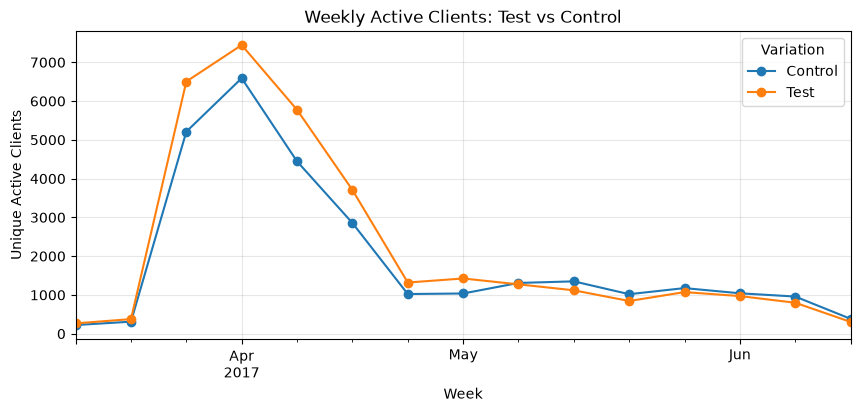

In [4]:
# Compare weekly activity between Test and Control
weekly_clients.plot(figsize=(10, 4), marker="o")

plt.title("Weekly Active Clients: Test vs Control")
plt.xlabel("Week")
plt.ylabel("Unique Active Clients")
plt.grid(alpha=0.3)
plt.show()

##### The experiment covered the full planned period, with both groups remaining active throughout. However, participation was uneven, with a strong peak in early April followed by a substantial decline.

### 3. Weekly Completion Rate Stability

In [5]:
# Find the first start and last confirm within each visit
starts = (
    experiment_events[experiment_events["process_step"] == "start"]
    .groupby(["client_id", "visit_id", "Variation"])["date_time"]
    .min()
    .reset_index(name="start_time")
)

confirms = (
    experiment_events[experiment_events["process_step"] == "confirm"]
    .groupby(["client_id", "visit_id", "Variation"])["date_time"]
    .max()
    .reset_index(name="confirm_time")
)

# Match starts with confirms
visits = starts.merge(
    confirms,
    on=["client_id", "visit_id", "Variation"],
    how="left"
)

visits["completed"] = visits["confirm_time"] >= visits["start_time"]
visits["week"] = visits["start_time"].dt.to_period("W").dt.start_time

# Calculate weekly completion rate per unique client
client_week = visits.groupby(
    ["week", "Variation", "client_id"]
)["completed"].max().reset_index()

weekly_completion = (
    client_week.groupby(["week", "Variation"])["completed"]
    .mean().unstack() * 100
)

display(weekly_completion.round(1))

Variation,Control,Test
week,,
2017-03-13,59.1,61.4
2017-03-20,51.6,58.0
2017-03-27,61.2,66.7
2017-04-03,49.2,53.9
2017-04-10,53.9,60.5
2017-04-17,53.0,60.8
2017-04-24,45.3,51.9
2017-05-01,41.5,52.1
2017-05-08,53.3,53.0


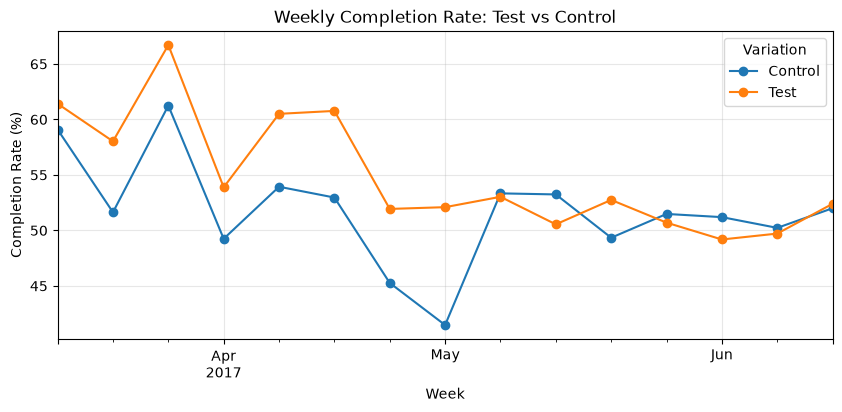

In [6]:
# Visualize completion rate stability
weekly_completion.plot(figsize=(10, 4), marker="o")

plt.title("Weekly Completion Rate: Test vs Control")
plt.xlabel("Week")
plt.ylabel("Completion Rate (%)")
plt.grid(alpha=0.3)
plt.show()

##### Weekly completion rates fluctuated during the early stages but became more stable toward the end of the experiment, suggesting that the longer duration helped capture more consistent performance patterns.

### 4. Cumulative Completion Rate Stability

In [7]:
# Calculate completed and total client-week observations
weekly_counts = client_week.groupby(
    ["week", "Variation"]
)["completed"].agg(["sum", "count"]).reset_index()

weekly_counts = weekly_counts.sort_values("week")

# Calculate cumulative completion rate
weekly_counts["total_completed"] = weekly_counts.groupby("Variation")["sum"].cumsum()
weekly_counts["total_clients"] = weekly_counts.groupby("Variation")["count"].cumsum()

weekly_counts["cumulative_rate"] = (
    weekly_counts["total_completed"] /
    weekly_counts["total_clients"] * 100
)

# Compare Test and Control over time
cumulative_rates = weekly_counts.pivot(
    index="week",
    columns="Variation",
    values="cumulative_rate"
)

display(cumulative_rates.round(2))

Variation,Control,Test
week,,
2017-03-13,59.09,61.42
2017-03-20,54.75,59.44
2017-03-27,60.65,66.07
2017-04-03,54.56,59.99
2017-04-10,54.39,60.13
2017-04-17,54.18,60.23
2017-04-24,53.74,59.82
2017-05-01,53.16,59.43
2017-05-08,53.17,59.15


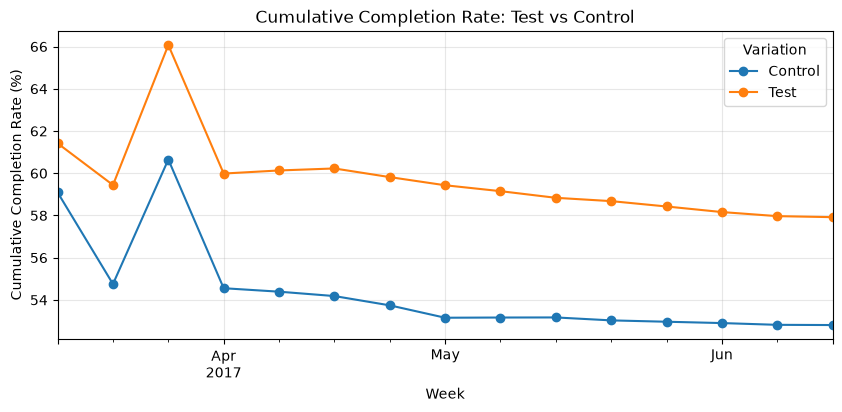

In [8]:
# Visualize cumulative completion rates
cumulative_rates.plot(figsize=(10, 4), marker="o")

plt.title("Cumulative Completion Rate: Test vs Control")
plt.xlabel("Week")
plt.ylabel("Cumulative Completion Rate (%)")
plt.grid(alpha=0.3)
plt.show()

**Conclusion: ADEQUATE, WITH LIMITATIONS**

The 14-week experiment was sufficient to gather meaningful insights. Both groups remained active throughout, and cumulative completion rates gradually stabilized. However, participation declined significantly, and the Test advantage narrowed in later weeks. The duration was adequate for analysis, but further monitoring would help confirm the long-term consistency of the results.